In [ ]:
# 基础库
import numpy as np
import xarray as xr
import os
import sys
import gc  
import pickle

# 统计分析库
import statsmodels.api as sm
from scipy.stats import norm, ttest_1samp
import pymannkendall as mk
from scipy.stats import pearsonr
from scipy.stats import linregress
from scipy import stats


# 可视化库
from matplotlib import gridspec, pyplot as plt
from matplotlib.lines import Line2D
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from matplotlib.colors import LinearSegmentedColormap
import warnings
warnings.filterwarnings("ignore")

# 自定义模块
sys.path.append('/public/home/zhujw/work/guoly/code/Self-package/ccg_filter')
import ccg_filter

def mk_test(x):
    ## mk检验，输入时间序列W后，输出对应的标准正态值
    S = 0
    n = len(x)
    for i in range(n - 1):
        for j in range(i + 1, n):
            S += np.sign(x[j] - x[i])
    data_sort = np.sort(x)
    num = 0
    nn = 0
    for i in range(len(x) - 1):
        if data_sort[i + 1] - data_sort[i] <= 1.0e-37:
            nn += 1
        else:
            num += nn * (nn - 1) * (2 * nn + 5)
            nn = 1
    var_s = (n * (n - 1) * (2 * n + 5) - num) / 18
    if S > 0:
        Z = (S - 1) / np.sqrt(var_s)
    elif S == 0:
        Z = 0
    elif S < 0:
        Z = (S + 1) / np.sqrt(var_s)

    return Z

def trend_window(AMP, min_line, cal_type=None, mk_type=None):
#    这个函数用来计算AMP的滑动窗口趋势，或者非滑动窗口趋势
#    AMP 原始序列 min_line 滑动窗口最小数 
#    当cal_type不为空时，使用gls方法计算b
    b = []
    p = []
    x = np.arange(1, len(AMP) + 1)
    line_start = x[:len(x) - min_line + 1]
    for i in range(len(line_start)):
        AMP_now = AMP[i:i + min_line]
        x_now = np.arange(1, min_line + 1)

        if cal_type is not None:
            x_now = sm.add_constant(x_now)
            gls_model = sm.GLS(AMP_now, x_now)
            gls_results = gls_model.fit()
            params = gls_results.params
            b.append(params[1])
            if mk_type is not None:
                p.append(1 - norm.cdf(mk_test(AMP_now[~np.isnan(AMP_now)]), 0, 1))
            else:
                result = mk.original_test(AMP_now)
                p.append(result.p)
        
        else:
            b0 = np.polyfit(x_now[~np.isnan(AMP_now)], AMP_now[~np.isnan(AMP_now)], 1)  # min_square的系数
            if mk_type is not None:
                p.append(1 - norm.cdf(mk_test(AMP_now[~np.isnan(AMP_now)]), 0, 1))
            else:
                result = mk.original_test(AMP_now)
                p.append(result.p)
            b.append(b0[0])

    Z = np.vstack((p, b))
    return Z

def cal_trend_diff(data, time, min_len, trend_select, p_threshold=0.1, site=None, ratio_flag=None):
    """
    计算数据的heatmap和时间映射

    Parameters:
    data : 一维数组，原始数据
    time : 一维数组，时间序列
    min_len : int，最小窗口长度，用于计算趋势
    trend_select : int，选取计算趋势差的窗口长度
    ratio_flag : True/False，是否返回趋势差的比值形式

    Returns:
    diff : 一维数组，包含趋势差
    sign_start : int，趋势开始的符号
    """
    len_amp = len(data)

    # 初始化 heat_map 和 time_map ([p, b], start_time, end_time)
    heat_map = np.full((2, len_amp - min_len, len_amp - min_len), np.nan)
    time_map = np.full((2, len_amp - min_len, len_amp - min_len), np.nan)

    # 计算趋势的 heat_map 和时间映射
    for i in range(len_amp - min_len):
        for j in range(i + min_len, len_amp):
            # # 1) 只保留「前 trend_select 行」和「最后 trend_select 行」
            # if i > trend_select and i < (len_amp - trend_select - min_len):
            #     continue
            # # 2) 只保留「窗口长度 <= trend_select」的对角线附近区域
            # if (j - i - min_len) > trend_select:
            #     continue
            amp_now = data[i:j]
            trend_result = trend_window(amp_now, j - i, cal_type=0, mk_type=1).squeeze()
            heat_map[:, i, j - min_len] = trend_result
            time_map[:, i, j - min_len] = [time[i], time[j]]

    # 计算趋势差 diff
    trend_start = heat_map[1, :trend_select, :trend_select]
    trend_end = heat_map[1, -trend_select:, -trend_select:]
    diff = trend_end - trend_start
    diff = diff[~np.isnan(diff)]
    print(f"Trend start: {np.nanmean(trend_start):.3f} \u00B1 {np.nanstd(trend_start):.3f}, Trend end: {np.nanmean(trend_end):.3f} \u00B1 {np.nanstd(trend_end):.3f}")

    # 计算显著性
    t, p_diff = ttest_1samp(diff.flatten(), popmean=0, nan_policy='omit')
    diff_mean = np.nanmean(diff)
    t_stat, p_start = ttest_1samp(trend_start.flatten(), popmean=0, nan_policy='omit')
    start_mean = np.nanmean(trend_start)
    t_end, p_end = ttest_1samp(trend_end.flatten(), popmean=0, nan_policy='omit')
    end_mean = np.nanmean(trend_end)

    if (p_diff > p_threshold) or (diff_mean == 0):
        sign = -1
    else:
        if diff_mean >= 0:
            if start_mean >= 0 and end_mean > 0: sign = 1
            elif start_mean <= 0 and end_mean >= 0: sign = 2
            elif start_mean < 0 and end_mean <= 0: sign = 3
        elif diff_mean < 0:
            if start_mean > 0 and end_mean >= 0: sign = 4
            elif start_mean >= 0 and end_mean <= 0: sign = 5
            elif start_mean <= 0 and end_mean < 0: sign = 6

    if ratio_flag:
        ratio = trend_end / trend_start
        ratio = ratio[~np.isnan(ratio)]
        return diff, sign, p_diff, ratio, heat_map, time_map
    else:
        return diff, sign, p_diff, heat_map, time_map

def p_to_stars(p):
    if p <= 0.001:
        return '***'
    elif p <= 0.05:
        return '**'
    elif p <= 0.1:
        return '*'
    else:
        return ''

def quad_fit(time, amp, deg=2, ci_k=1.96):
    """
    deg: 多项式阶数，默认二次
    ci_k: 置信区间倍数，默认 1.96 95% 置信区间

    对 (time, amp) 做二次多项式拟合，返回：
      time_fit   : 拟合曲线用的时间（与 time 同单位）
      amp_fit    : 拟合曲线值
      amp_lower  : 置信区间下界（整体残差 std 方法）
      amp_upper  : 置信区间上界
      p_overall  : 整体回归 F 检验 p 值
      coeffs     : 多项式系数 np.polyfit 返回的 p
    """
    time = np.asarray(time, dtype=float)
    amp  = np.asarray(amp,  dtype=float)

    # 平移时间以减小共线性问题
    t0   = time.mean()
    t_rel = time - t0
    coeffs = np.polyfit(t_rel, amp, deg) 
    
    # 拟合曲线
    t_fit = np.linspace(t_rel.min(), t_rel.max(), 200)
    amp_fit = np.polyval(coeffs, t_fit)

    # 预测值与残差（在原始采样点上）
    amp_pred = np.polyval(coeffs, t_rel)
    residuals = amp - amp_pred

    # 残差标准差（整体噪声水平）
    sigma = residuals.std(ddof=1)

    # 简单置信区间（不区分 x 位置）：amp_fit ± k·sigma
    amp_upper = amp_fit + ci_k * sigma
    amp_lower = amp_fit - ci_k * sigma

    # ---------- 计算整体回归 p 值（F 检验） ----------
    n = len(amp)
    p_params = deg + 1              # 二次 = 3 个系数
    ss_tot = np.sum((amp - amp.mean())**2)
    ss_reg = np.sum((amp_pred - amp.mean())**2)
    ss_res = np.sum((amp - amp_pred)**2)

    dof_reg = p_params - 1
    dof_res = n - p_params
    r2 = ss_reg / ss_tot

    if dof_res > 0 and ss_res > 0:
        ms_reg = ss_reg / dof_reg
        ms_res = ss_res / dof_res
        F = ms_reg / ms_res
        p_overall = 1 - stats.f.cdf(F, dof_reg, dof_res)
    else:
        p_overall = np.nan

    # 把 t_fit 平移回原始时间
    time_fit = t_fit + t0

    return time_fit, amp_fit, amp_lower, amp_upper, p_overall, r2

In [4]:
site_folder = '/public/home/zhujw/work/guoly/code/Paper-3-Acceleration-Boreal/manuscript-code/data/Fig-1-site+model/'
files = os.listdir(site_folder)
files.sort()

site_dict = {}
model_dict = {}
model_list = ['MBL', 'XCO2', 'CAMS-GC', 'Jena-GC', 'Trendy-GC']

for file in files:
    if not file.endswith('.nc'):
        continue
        
    site_name = file.split('.')[0]
    file_path = os.path.join(site_folder, file)
    
    with xr.open_dataset(file_path) as ds:
        time = ds['time'].values
        diff, sign, p_diff, ratio, trend_map, time_map = cal_trend_diff(ds['amp'].values, time, min_len=20, trend_select=8, site=site_name, ratio_flag=True)

        data_info = {
            'time': time,
            'amp': ds['amp_new'].values,
            'diff': diff,
            'sign': sign,
            'p_diff': p_diff,
            'ratio': ratio,
            'trend_map': trend_map,
            'time_map': time_map
        }
        
    # 根据名称分别存入站点或模型字典
    if site_name in model_list:
        model_dict[site_name] = data_info
    else:
        site_dict[site_name] = data_info

Trend start: 0.079 ± 0.013, Trend end: 0.125 ± 0.009
Trend start: 0.086 ± 0.024, Trend end: 0.123 ± 0.012
Trend start: 0.075 ± 0.009, Trend end: 0.140 ± 0.014
Trend start: 0.039 ± 0.014, Trend end: 0.010 ± 0.034
Trend start: 0.112 ± 0.036, Trend end: 0.160 ± 0.013
Trend start: 0.070 ± 0.025, Trend end: 0.086 ± 0.030
Trend start: 0.059 ± 0.011, Trend end: 0.082 ± 0.016
Trend start: 0.029 ± 0.012, Trend end: 0.099 ± 0.012
Trend start: 0.062 ± 0.013, Trend end: 0.071 ± 0.010
Trend start: 0.115 ± 0.007, Trend end: 0.161 ± 0.017
Trend start: 0.035 ± 0.037, Trend end: 0.053 ± 0.044
Trend start: 0.054 ± 0.047, Trend end: 0.033 ± 0.033
Trend start: 0.089 ± 0.006, Trend end: 0.140 ± 0.013
Trend start: 0.048 ± 0.004, Trend end: 0.086 ± 0.006


0.5422952586206897 0.41


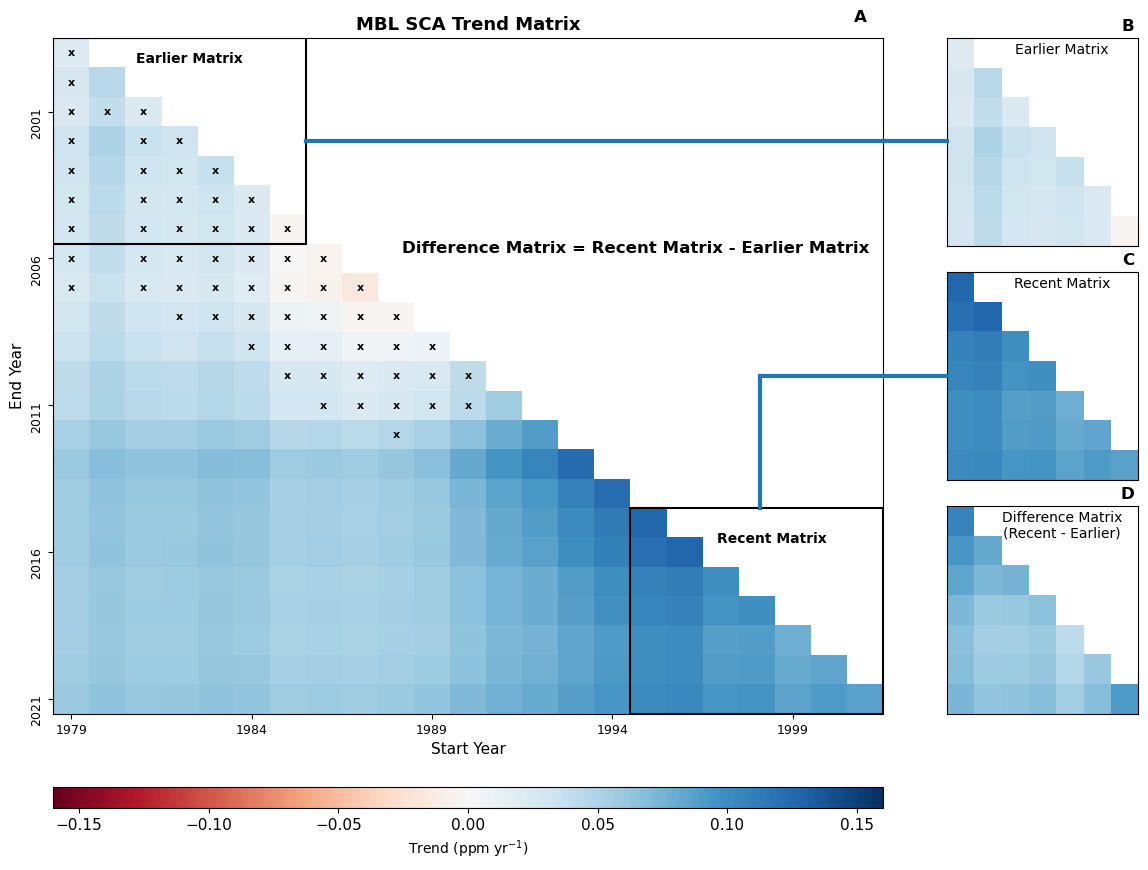

In [5]:
# Trend matrix - 只绘制 MBL（使用 GridSpec）

import matplotlib.gridspec as gridspec
from matplotlib.patches import FancyBboxPatch
import matplotlib.patches as mpatches

fig = plt.figure(figsize=(14, 10))

# 创建 GridSpec
gs = gridspec.GridSpec(5, 3, figure=fig, height_ratios=[1, 1, 1, 0.1, 0.1], 
                       width_ratios=[2, 2, 1], hspace=0.2, wspace=0.2)

# 主图占据左上和中间（跨行）
ax_main = fig.add_subplot(gs[0:3, 0:2])

# 只提取 MBL 数据
site = 'MBL'
info = model_dict[site]

# 提取矩阵数据
trend_map = info['trend_map'][1]
p_map = info['trend_map'][0]
time_map = info['time_map'] 
time_max = np.nanmax(time_map)
time_min = np.nanmin(time_map)

x_tick = np.arange(time_min + 20, time_max + 1)          # End year
y_tick = np.arange(time_min, time_max + 1 - 20)          # Start year

# 旋转/翻转矩阵以匹配坐标展示
flipped = np.flipud(np.rot90(trend_map, k=1))                   # 主值
annot_raw = np.flipud(np.rot90(p_map, k=1))                 # 显著性辅助
annot = np.where(annot_raw > 0.1, 'x', '')

# ================= 上下反转 =================
flipped = np.flipud(flipped)
annot = np.flipud(annot)

n = flipped.shape[0]
box_size = 7

# ==========================================
# 主图：用 pcolormesh 绘制 heatmap
# ==========================================
im = ax_main.pcolormesh(flipped, cmap='RdBu', vmin=-0.16, vmax=0.16, shading='auto')

# 添加 'x' 标记（不标注数值）
for i in range(flipped.shape[0]):
    for j in range(flipped.shape[1]):
        if annot[i, j] == 'x':
            ax_main.text(j + 0.5, i + 0.5, 'x', ha='center', va='center', 
                   color='black', fontsize=8, fontweight='bold')

# 设置刻度
x_idx = np.arange(0, len(y_tick), 5)
y_idx = np.arange(0, len(x_tick), 5)

ax_main.set_xticks(x_idx + 0.5)
ax_main.set_xticklabels(np.array(y_tick)[x_idx].astype(int), fontsize=9, rotation=0)

ax_main.set_yticks(y_idx + 0.5)
ax_main.set_yticklabels(np.array(x_tick)[::-1][y_idx].astype(int), fontsize=9, rotation=90)

# 轴标签
ax_main.set_xlabel('Start Year', fontsize=11)
ax_main.set_ylabel('End Year', fontsize=11)
ax_main.set_title('MBL SCA Trend Matrix', fontsize=13, fontweight='bold')

# ==========================================
# 绘制黑色方框
# ==========================================
from matplotlib.patches import Rectangle

# 左下三角方框（早期窗口）
lower_left_box = Rectangle((0, n - box_size), box_size, box_size, 
                           linewidth=1.5, edgecolor='black', facecolor='none', zorder=10)
ax_main.add_patch(lower_left_box)

# 右上三角方框（晚期窗口）
upper_right_box = Rectangle((n - box_size, 0), box_size, box_size, 
                            linewidth=1.5, edgecolor='black', facecolor='none', zorder=10)
ax_main.add_patch(upper_right_box)

ax_main.set_xlim(0, n)
ax_main.set_ylim(0, n)

# ==========================================
# 右侧：显示两个小矩阵和差值矩阵（用 pcolormesh）
# ==========================================

# 提取两个小矩阵
early_matrix = flipped[n-box_size:n, 0:box_size]
late_matrix = flipped[0:box_size, n-box_size:n]
diff_matrix = late_matrix - early_matrix

# 右上小图：早期矩阵
ax_early = fig.add_subplot(gs[0, 2])
im_early = ax_early.pcolormesh(early_matrix, cmap='RdBu', vmin=-0.16, vmax=0.16, shading='auto')
ax_early.text(0.6, 0.98, 'Earlier Matrix', fontsize=10, va='top', ha='center',
             transform=ax_early.transAxes)
ax_early.set_xticks([])
ax_early.set_yticks([])

# 右中小图：晚期矩阵
ax_late = fig.add_subplot(gs[1, 2])
im_late = ax_late.pcolormesh(late_matrix, cmap='RdBu', vmin=-0.16, vmax=0.16, shading='auto')
ax_late.text(0.6, 0.98, 'Recent Matrix', fontsize=10, va='top', ha='center',
             transform=ax_late.transAxes)
ax_late.set_xticks([])
ax_late.set_yticks([])

# 右下小图：差值矩阵
ax_diff = fig.add_subplot(gs[2, 2])
im_diff = ax_diff.pcolormesh(diff_matrix, cmap='RdBu', vmin=-0.16, vmax=0.16, shading='auto')
ax_diff.text(0.6, 0.98, 'Difference Matrix\n(Recent - Earlier)', fontsize=10, va='top', ha='center',
             transform=ax_diff.transAxes)
ax_diff.set_xticks([])
ax_diff.set_yticks([])

# ==========================================
# Colorbar 在下方（跨越左右两部分）
# ==========================================
cbar_ax = fig.add_subplot(gs[-1, :2])
cbar = fig.colorbar(im, cax=cbar_ax, orientation='horizontal', label='Trend (ppm yr$^{-1}$)')
cbar.ax.tick_params(labelsize=11)

# ==========================================
# 绘制连接线（水平竖直）
# ==========================================
# 获取各坐标轴在 figure 坐标系中的位置
pos_main = ax_main.get_position()
pos_early = ax_early.get_position()
pos_late = ax_late.get_position()

# Early period 连接线（水平+竖直）
early_start_x = pos_main.x1  # main 的右边界
early_start_y = pos_main.y1 - (pos_main.y1 - pos_main.y0) * (box_size / 2 / n)  # 早期方框的中点y

early_end_x = pos_early.x0  # ax_early 的左边界
early_end_y = pos_early.y1 - (pos_early.y1 - pos_early.y0) * 0.5  # ax_early 的中点y

# 先画水平线，再画竖直线
fig.add_artist(plt.Line2D([0.3052, early_end_x], [early_start_y, early_start_y],
                          transform=fig.transFigure, linewidth=3, zorder=5))

# Late period 连接线（水平+竖直）
late_start_x = pos_main.x1
late_start_y = 0.41

late_end_x = pos_late.x0
late_end_y = pos_late.y1 - (pos_late.y1 - pos_late.y0) * 0.5  # ax_late 的中点y

print(late_end_y, late_start_y)

# 先画水平线，再画竖直线
x_pos = 0.63
fig.add_artist(plt.Line2D([x_pos, late_end_x], [late_end_y, late_end_y],
                          transform=fig.transFigure, linewidth=3, zorder=5))
fig.add_artist(plt.Line2D([x_pos, x_pos], [late_start_y, late_end_y],
                          transform=fig.transFigure, linewidth=3, zorder=5))

ax_main.text(0.1, 0.98, 'Earlier Matrix', fontsize=10, va='top', ha='left',
             transform=ax_main.transAxes, fontweight='bold')
ax_main.text(0.8, 0.27, 'Recent Matrix', fontsize=10, va='top', ha='left',
             transform=ax_main.transAxes, fontweight='bold')
ax_main.text(0.42, 0.7, 'Difference Matrix = Recent Matrix - Earlier Matrix', fontsize=12, va='top', ha='left',
             transform=ax_main.transAxes, fontweight='bold')
letters = ['A', 'B', 'C', 'D']
for i, ax in enumerate([ax_main, ax_early, ax_late, ax_diff]):
    ax.text(0.98, 1.02, letters[i], transform=ax.transAxes, fontsize=12, 
            fontweight='bold', ha='right', va='bottom')

fig.savefig('/public/home/zhujw/work/guoly/code/Paper-3-Acceleration-Boreal/manuscript-code/SI-fig/Part-1-DiffMatrix.png', 
            dpi=500, bbox_inches='tight', pad_inches=0.1)
plt.show()